# E · Forecasting: what will tomorrow look like?

**Purpose.** At midnight, forecast each hour of the coming day for every floor, to warn of an unusual peak or to plan
pre-cooling. **How it is tested.** A rolling backtest over Jul–Dec 2019: each week the model is refitted on all data
up to that point, then forecasts the next seven days one day at a time. **Benchmark.** *Seasonal naive*, which simply
predicts that each hour will match the same hour on the same weekday last week. A model is only worth using if it
beats this simple rule.

| Model | Inputs |
|---|---|
| seasonal naive | load 168 hours (one week) earlier |
| persistence | load 24 hours (one day) earlier |
| TOWT | weather + calendar (the baseline from B) |
| gradient boosting + lags | weather + calendar + load 24 and 168 hours earlier |

**Caveat.** The weather inputs are the *actual* weather from ERA5, as if the weather forecast were perfect. Real
day-ahead accuracy will be lower.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="obj.round has no effect")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# `pip install -e .` from the repo root makes `sbanalytics` importable; this fallback works without it.
try:
    import sbanalytics
except ImportError:
    import sys
    from pathlib import Path
    sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sbanalytics").is_dir()) / "src"))

from sbanalytics import data as D, registry as R, viz
viz.setup()
pd.set_option("display.precision", 2)
pd.set_option("display.width", 160)
from sbanalytics import baseline as B, forecast as FC, config as C

In [2]:
h = D.load_hourly(None)
fh = B.floor_hourly(h)
fd = B.floor_daily(fh)
OFFICE = [2, 3, 4, 5, 6, 7]     # F1 has no AC schedule (00a §5): excluded from schedule-based measures

In [3]:
bt = FC.backtest(fh, "total_kwh")
sc = FC.score(bt)
sc.pivot_table(index="floor", columns="model", values="skill_vs_naive").round(2)

model,GBM + lags,TOWT (weather + calendar),persistence_24h,seasonal_naive
floor,,,,
1,0.17,0.11,-0.03,0.0
2,0.50,0.26,-0.53,0.0
3,0.66,0.59,-0.85,0.0
4,0.63,0.61,-0.76,0.0
5,0.66,0.60,-0.86,0.0
6,0.61,0.57,-0.85,0.0
7,0.48,0.43,-0.57,0.0


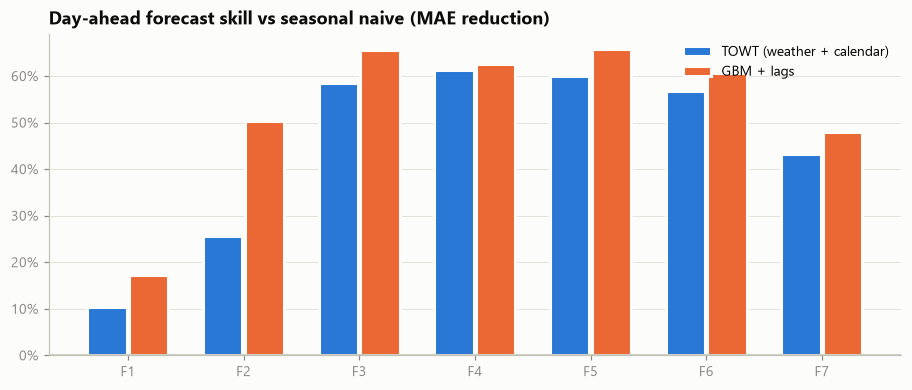

In [4]:
sk = sc.pivot_table(index="floor", columns="model", values="skill_vs_naive")[FC.MODELS[2:]]
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(sk))
for i, m in enumerate(sk.columns):
    ax.bar(x + (i - 0.5) * 0.36, sk[m], width=0.34, color=viz.CATEGORICAL[i], label=m, edgecolor=viz.SURFACE, linewidth=2)
ax.set_xticks(x, [f"F{f}" for f in sk.index]); ax.axhline(0, color=viz.AXIS, lw=1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.grid(axis="x", visible=False)
ax.set_title("Day-ahead forecast skill vs seasonal naive (MAE reduction)"); ax.legend(loc="upper right")

In [5]:
sc.pivot_table(index="floor", columns="model", values="cv_rmse").round(1)

model,GBM + lags,TOWT (weather + calendar),persistence_24h,seasonal_naive
floor,,,,
1,25.3,27.1,33.4,32.2
2,22.7,28.0,86.9,59.2
3,20.1,23.4,124.2,78.6
4,25.9,21.9,122.6,81.0
5,18.7,22.1,124.3,77.5
6,17.6,19.5,115.0,69.7
7,35.3,34.6,114.0,79.7


Seasonal naive does poorly here because a single holiday or outage in the previous week carries straight into the
next week's forecast. Persistence (copying yesterday) does even worse, because it copies Friday's load into Saturday.

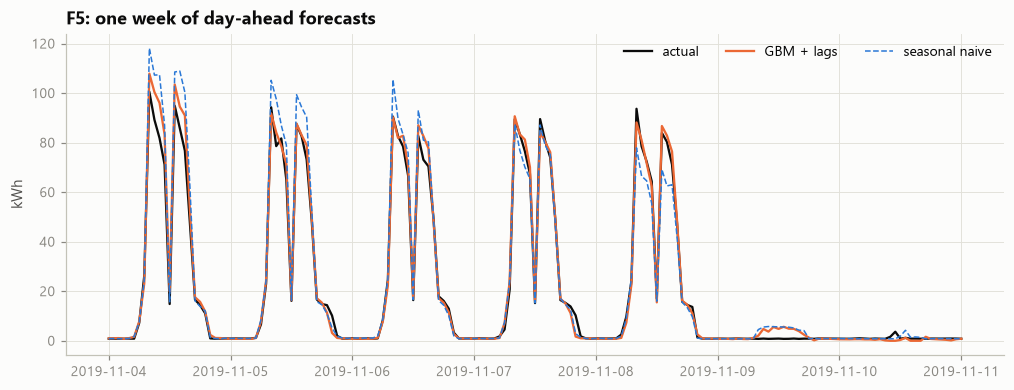

In [6]:
FLOOR, start = 5, pd.Timestamp("2019-11-04")
g = bt[(bt.floor == FLOOR) & bt.ts.between(start, start + pd.Timedelta(days=7))]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(g.ts, g.actual, color=viz.INK, lw=1.5, label="actual")
ax.plot(g.ts, g["GBM + lags"], color=viz.CATEGORICAL[1], lw=1.5, label="GBM + lags")
ax.plot(g.ts, g.seasonal_naive, color=viz.CATEGORICAL[0], lw=1, ls="--", label="seasonal naive")
ax.set_ylabel("kWh"); ax.set_title(f"F{FLOOR}: one week of day-ahead forecasts"); ax.legend(ncol=3, loc="upper right")

In [7]:
hit = FC.peak_hit_rate(bt, "GBM + lags").rename("GBM: peak hour within ±1 h")
hit_n = FC.peak_hit_rate(bt, "seasonal_naive").rename("naive: peak hour within ±1 h")
pd.concat([hit, hit_n], axis=1).style.format("{:.0%}")

,GBM: peak hour within ±1 h,naive: peak hour within ±1 h
floor,,
1,82%,74%
2,51%,36%
3,63%,55%
4,69%,65%
5,65%,55%
6,53%,42%
7,46%,41%


**Conclusion.** Forecasting is only worth having on floors where it clearly beats the naive benchmark; the table above
shows which ones. Its main practical use is **warning of peaks and planning pre-cooling**. A facilities manager will
use the baseline (B), the comparison (C) and the fault list (D) far more often than a forecast, which is why
forecasting has a lower priority in this project.